# Airfoil Self-Noise — Linear Regression

Predict the **scaled sound pressure level (SPL, dB)** of an aerofoil from five aerodynamic parameters with ordinary least squares.

**Dataset:** [UCI Airfoil Self-Noise](https://archive.ics.uci.edu/dataset/291/airfoil+self+noise) — 1,503 wind-tunnel measurements (NASA) · **Target:** scaled sound pressure level [dB] · **License:** CC BY 4.0

Every step below calls the reusable `airfoil_noise` package; running `uv run airfoil-run` reproduces the same figures and metrics outside the notebook.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from airfoil_noise.data import (
    FEATURE_META,
    FEATURES,
    FEATURES_WITH_LOG,
    add_log_frequency,
    clean_data,
    load_data,
    split_xy,
)
from airfoil_noise.modeling import (
    SEED,
    coefficient_table,
    cross_validate_r2,
    evaluate,
    make_pipeline,
    split,
    tune_regularized,
)
from airfoil_noise.plots import (
    plot_actual_vs_predicted,
    plot_coefficients,
    plot_correlation_heatmap,
    plot_feature_vs_target,
    plot_model_comparison,
    plot_residual_distribution,
    plot_residuals_vs_fitted,
)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
FIGURES = PROJECT_ROOT / "reports" / "figures"
pd.set_option("display.precision", 4)
SEED

42

## 1. Load and clean the data

Cleaning policy: coerce to numeric, enforce broad physical ranges, then drop duplicate rows. The raw file has no missing values, so the goal is a reproducible audit trail rather than aggressive filtering.

In [2]:
raw = load_data()
clean_df, cleaning = clean_data(raw)
display(pd.Series(cleaning, name="rows"))
clean_df.head()

raw_rows              1503
invalid_or_missing       0
duplicates               0
final_rows            1503
Name: rows, dtype: int64

,frequency_hz,angle_of_attack_deg,chord_length_m,free_stream_velocity_ms,suction_side_displacement_thickness_m,scaled_sound_pressure_level_db
0,800,0.0,0.3048,71.3,0.0027,126.201
1,1000,0.0,0.3048,71.3,0.0027,125.201
2,1250,0.0,0.3048,71.3,0.0027,125.951
3,1600,0.0,0.3048,71.3,0.0027,127.591
4,2000,0.0,0.3048,71.3,0.0027,127.461


### Summary statistics

In [3]:
clean_df.describe().T

,count,mean,std,min,25%,50%,75%,max
frequency_hz,1503.0,2886.3806,3152.5731,200.0000,800.0000,1600.0000,4000.0000,20000.0000
angle_of_attack_deg,1503.0,6.7823,5.9181,0.0000,2.0000,5.4000,9.9000,22.2000
chord_length_m,1503.0,0.1365,0.0935,0.0254,0.0508,0.1016,0.2286,0.3048
free_stream_velocity_ms,1503.0,50.8607,15.5728,31.7000,39.6000,39.6000,71.3000,71.3000
suction_side_displacement_thickness_m,1503.0,0.0111,0.0132,0.0004,0.0025,0.0050,0.0156,0.0584
scaled_sound_pressure_level_db,1503.0,124.8359,6.8987,103.3800,120.1910,125.7210,129.9955,140.9870


## 2. Exploratory analysis

Frequency spans nearly two orders of magnitude, so that panel uses a log x-axis. SPL is strongly related to frequency and velocity, while angle of attack and displacement thickness contribute structure that a linear model cannot fully capture.

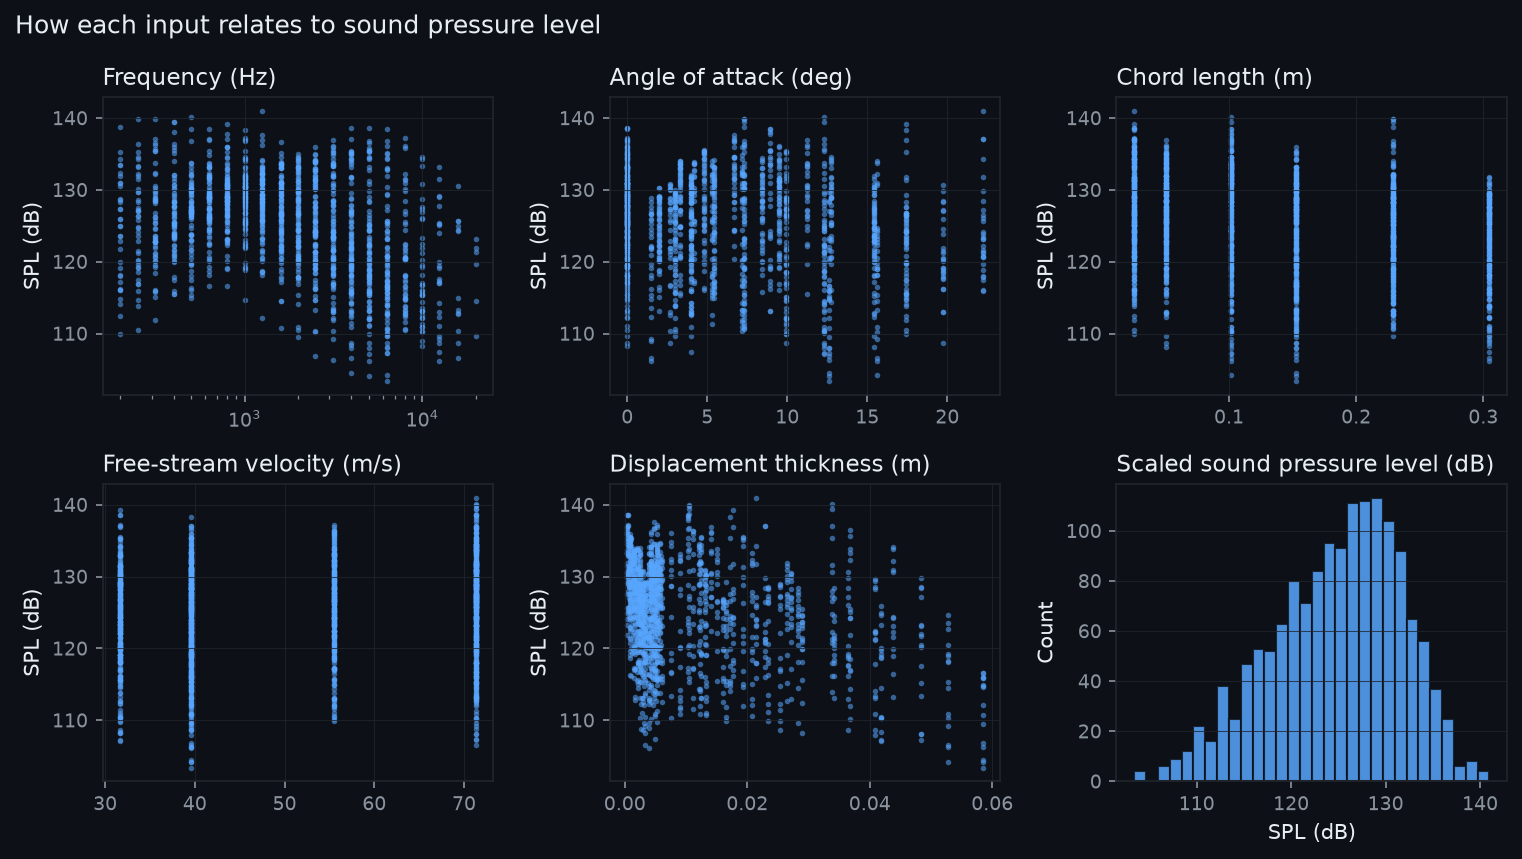

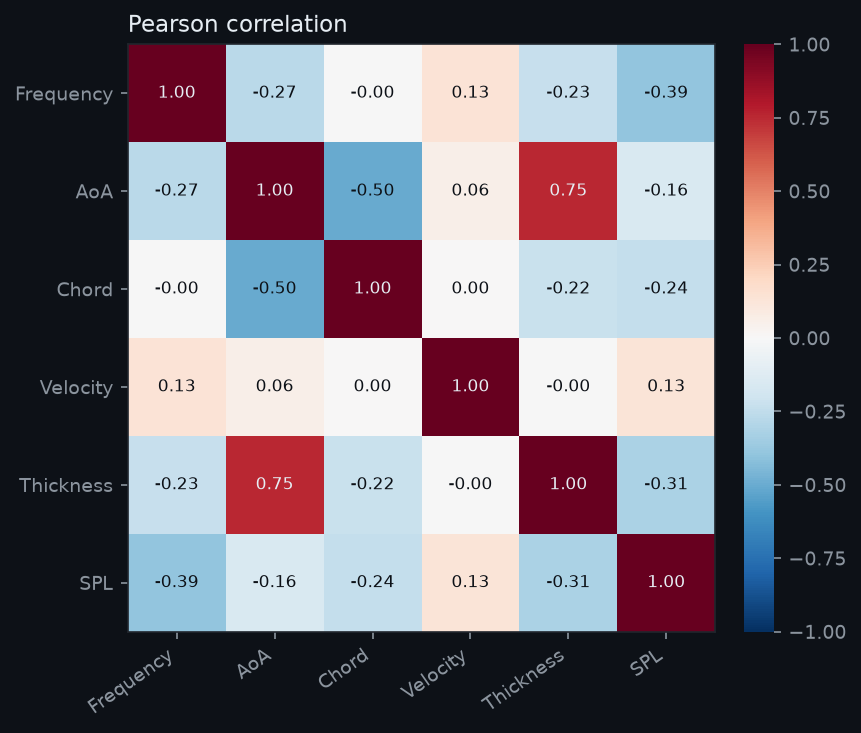

In [4]:
display(Image(filename=str(plot_feature_vs_target(clean_df, FIGURES / "feature_vs_target.png"))))
display(Image(filename=str(plot_correlation_heatmap(clean_df, FIGURES / "correlation_heatmap.png"))))

## 3. Baseline OLS

An 80/20 hold-out split (seed 42) with features standardised inside a scikit-learn pipeline, plus 5-fold cross-validation for a more stable estimate.

In [5]:
X, y = split_xy(clean_df)
X_train, X_test, y_train, y_test = split(X, y, random_state=SEED)

ols = make_pipeline().fit(X_train, y_train)
ols_metrics = evaluate(ols, X_test, y_test)
cv_mean, cv_std = cross_validate_r2(ols, X, y, random_state=SEED)

pd.DataFrame(
    [{**ols_metrics, "cv_r2_mean": cv_mean, "cv_r2_std": cv_std}], index=["OLS"]
)

,r2,rmse,mae,cv_r2_mean,cv_r2_std
OLS,0.5583,4.7041,3.6724,0.5051,0.0519


## 4. What the coefficients mean

Because the inputs are standardised, each coefficient is the SPL change (dB) for a one-standard-deviation increase in that feature, holding the others constant.

,feature,coefficient
0,Frequency (Hz),-4.0594
1,Chord length (m),-3.2200
2,Angle of attack (deg),-2.3667
3,Displacement thickness (m),-1.8156
4,Free-stream velocity (m/s),1.5269


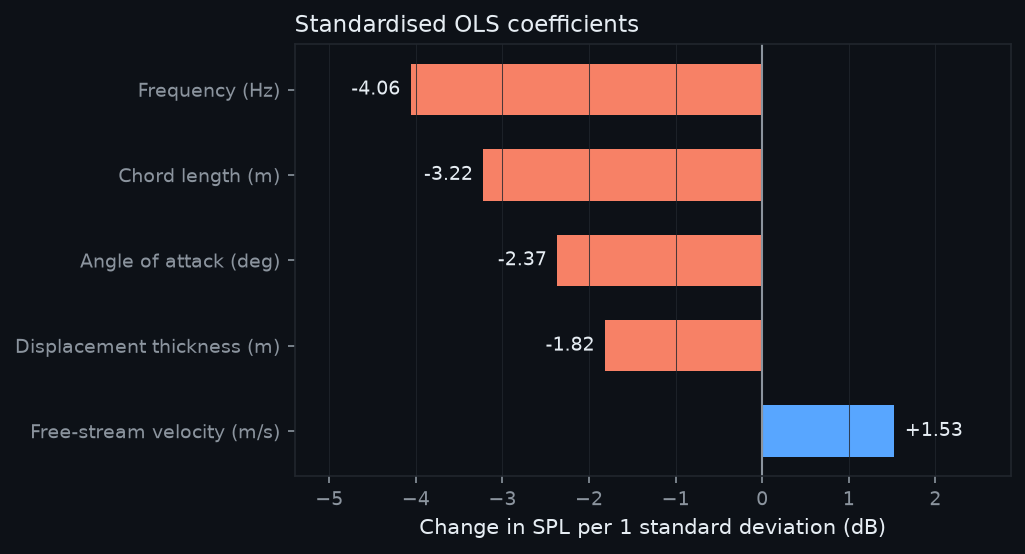

In [6]:
coef_table = coefficient_table(ols, FEATURES)
display(
    coef_table.assign(
        feature=coef_table["feature"].map(
            lambda key: f"{FEATURE_META[key]['label']} ({FEATURE_META[key]['unit']})"
        )
    )
)
display(Image(filename=str(plot_coefficients(coef_table, FIGURES / "coefficients.png"))))

## 5. Residual diagnostics

A well-specified linear model produces residuals that look like unstructured noise around zero. Here the structure in the residual plots shows that important curvature is left on the table.

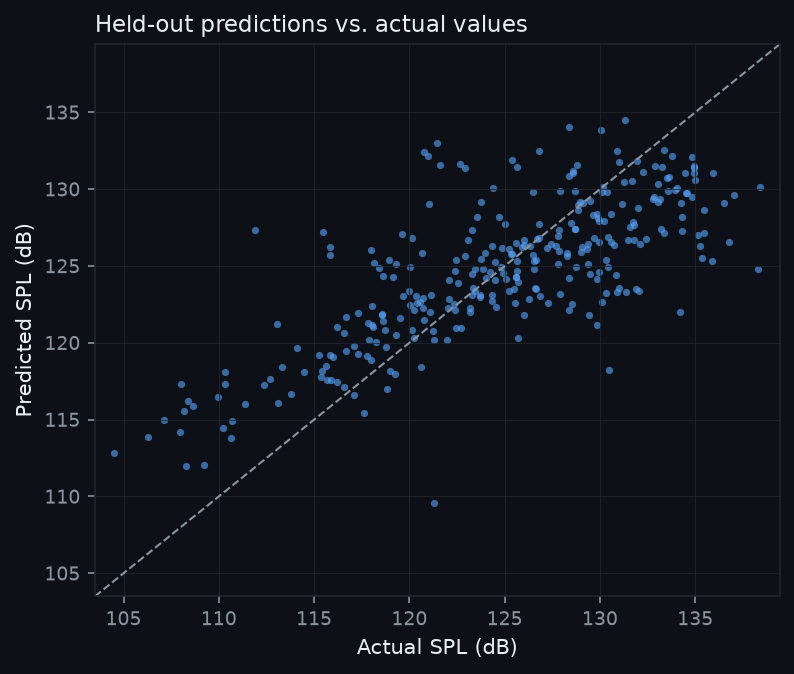

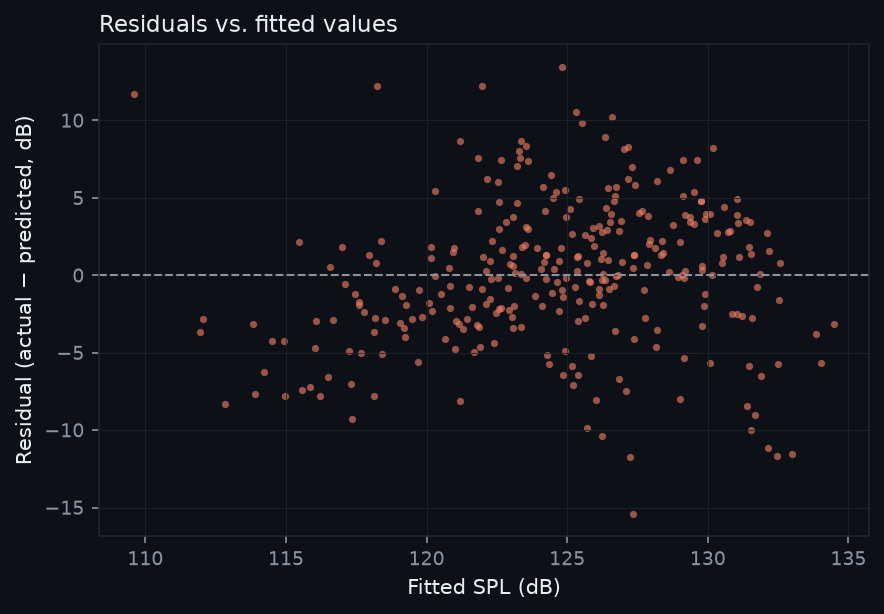

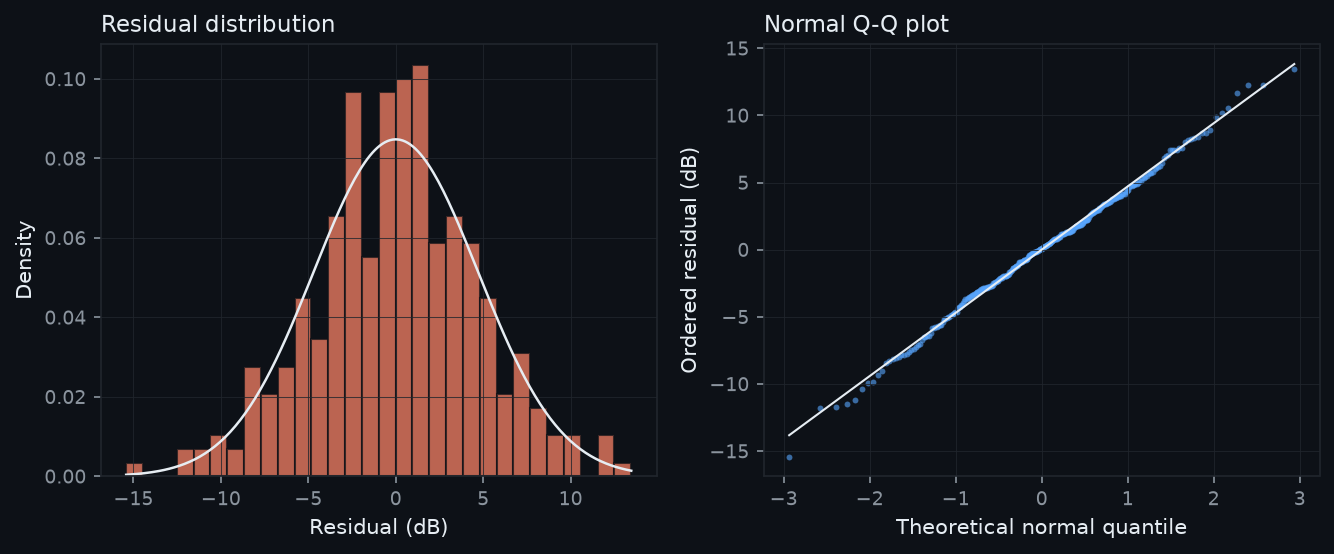

In [7]:
y_pred = ols.predict(X_test)
residuals = y_test.to_numpy() - y_pred

display(Image(filename=str(plot_actual_vs_predicted(y_test, y_pred, FIGURES / "actual_vs_predicted.png"))))
display(Image(filename=str(plot_residuals_vs_fitted(y_pred, residuals, FIGURES / "residuals_vs_fitted.png"))))
display(Image(filename=str(plot_residual_distribution(residuals, FIGURES / "residual_distribution.png"))))

## 6. Does regularisation help?

Ridge and Lasso are tuned with cross-validated alpha grids. Angle of attack and displacement thickness are correlated (r ≈ 0.75), but five features on more than 1,200 training rows leave little variance to shrink, so the regularised fits should stay close to OLS.

,model,alpha,r2,rmse,mae
0,OLS,NaN,0.5583,4.7041,3.6724
1,Ridge,10.000,0.5566,4.7130,3.6866
2,Lasso,0.001,0.5582,4.7045,3.6730


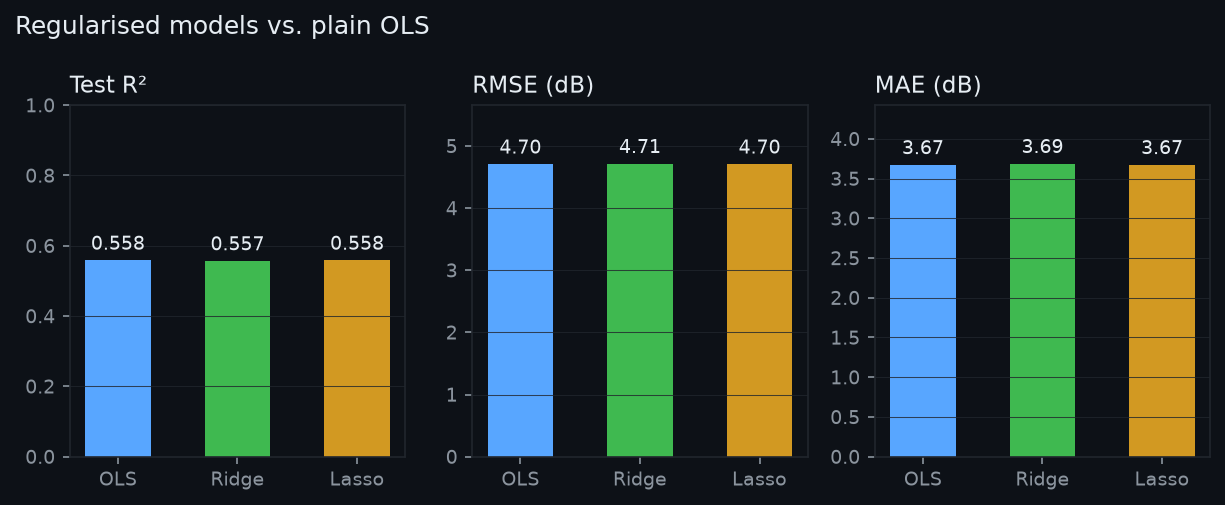

In [8]:
comparison = tune_regularized(X_train, y_train, X_test, y_test)
comparison = pd.concat(
    [pd.DataFrame([{"model": "OLS", "alpha": float("nan"), **ols_metrics}]), comparison],
    ignore_index=True,
)
display(comparison)
display(Image(filename=str(plot_model_comparison(comparison, FIGURES / "model_comparison.png"))))

## 7. One feature-engineering aside: log(frequency)

Sound pressure level is close to log-linear in frequency. Adding `log(frequency)` as a sixth feature tests whether that known structure is worth modelling explicitly.

In [9]:
log_X = add_log_frequency(clean_df).loc[:, FEATURES_WITH_LOG]
X_log_train, X_log_test, y_log_train, y_log_test = split(log_X, y, random_state=SEED)

log_model = make_pipeline().fit(X_log_train, y_log_train)
log_metrics = evaluate(log_model, X_log_test, y_log_test)
log_cv_mean, log_cv_std = cross_validate_r2(log_model, log_X, y, random_state=SEED)

pd.DataFrame(
    {
        "OLS (5 features)": {**ols_metrics, "cv_r2_mean": cv_mean},
        "OLS + log(frequency)": {**log_metrics, "cv_r2_mean": log_cv_mean},
    }
).T

,r2,rmse,mae,cv_r2_mean
OLS (5 features),0.5583,4.7041,3.6724,0.5051
OLS + log(frequency),0.5663,4.6614,3.6362,0.5171


## 8. Findings and limitations

In [10]:
best = comparison.loc[comparison["model"] != "OLS"].sort_values("r2", ascending=False).iloc[0]
display(
    Markdown(
        f"""
### Findings

- **Baseline fit:** test R² = **{ols_metrics['r2']:.3f}**, RMSE = **{ols_metrics['rmse']:.2f} dB**, MAE = **{ols_metrics['mae']:.2f} dB**.
- **Stability:** 5-fold CV R² = **{cv_mean:.3f} ± {cv_std:.3f}**, close to the hold-out score.
- **Regularisation:** the best regularised model ({best['model']}, alpha = {best['alpha']:.3f}) reaches R² = {best['r2']:.3f} versus {ols_metrics['r2']:.3f} for OLS — no material gain.
- **log(frequency):** test R² moves from {ols_metrics['r2']:.3f} to {log_metrics['r2']:.3f} ({log_metrics['r2'] - ols_metrics['r2']:+.3f}); the linear model already absorbs most of that trend.

### Limitations

- Residual plots show curvature and heteroscedasticity, so this is a baseline rather than the final word.
- Measurements share aerofoil geometry and wind-tunnel conditions; a random split overstates generalisation to new aerofoils.
- The validate-and-dedupe policy keeps every physically valid row, including extreme regimes.
"""
    )
)


### Findings

- **Baseline fit:** test R² = **0.558**, RMSE = **4.70 dB**, MAE = **3.67 dB**.
- **Stability:** 5-fold CV R² = **0.505 ± 0.052**, close to the hold-out score.
- **Regularisation:** the best regularised model (Lasso, alpha = 0.001) reaches R² = 0.558 versus 0.558 for OLS — no material gain.
- **log(frequency):** test R² moves from 0.558 to 0.566 (+0.008); the linear model already absorbs most of that trend.

### Limitations

- Residual plots show curvature and heteroscedasticity, so this is a baseline rather than the final word.
- Measurements share aerofoil geometry and wind-tunnel conditions; a random split overstates generalisation to new aerofoils.
- The validate-and-dedupe policy keeps every physically valid row, including extreme regimes.


## Reproduce

```bash
uv sync
uv run airfoil-run                 # data, metrics, figures, model, web payload
uv run jupyter lab                 # open this notebook interactively
open web/index.html                # static prediction demo (no server needed)
```